# Topic Analysis - Research Document Mining
Search engines index thousands of new research publications each year, making it increasingly challenging for researchers
and analysts to identify emerging trends and monitor the evolution of research topics. To address this challenge, you have
been tasked with designing a prototype system for tracking research trends in the field of artificial intelligence. As a proof of
concept, the system will apply topic modelling techniques to a small collection of recent AI research articles provided in the
research_corpus.zip dataset, with the aim of uncovering the main themes and research directions represented in the corpus.


In [43]:
# load libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation

### Article ingestion and validation
The analysis uses the five supplied research text files. The code checks for missing files and supports either extracted text files or the original ZIP archive. Each article is retained as a separate document, with its original content preserved for comparison.

In [44]:
# load data
path = Path("../data")

files = sorted(path.glob("research_[1-5].txt"))

corpus = pd.DataFrame([
    {
        "article_id": file.stem,
        "content": file.read_text(encoding="utf-8-sig")
    }
    for file in files
])

In [45]:
# inspect data
corpus["word_count"] = corpus["content"].str.split().str.len()
corpus["character_count"] = corpus["content"].str.len()

print(corpus[["article_id", "word_count", "character_count"]].to_string(index=False))

article_id  word_count  character_count
research_1        5602            38160
research_2        2416            16104
research_3        3828            26154
research_4        5922            38950
research_5        4027            26831


### Denoising decisions
URLs, email addresses, invisible characters, standalone page numbers and reference sections are removed where identifiable. Scientific punctuation and Unicode letters are preserved to avoid losing meaningful terminology. For summarisation, stopword removal and stemming are not applied to the original sentences because they can damage readability; TF-IDF handles stopwords at the feature-extraction stage. The cleaned texts are checked for empty documents and compared with their original lengths. PDF extraction artefacts are heterogeneous, so some may require document-specific review.

In [46]:
# preprocess text
def clean_article(text):
    # remove URLs, emails and invisible characters
    text = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", text)
    text = re.sub(r"[\u200b-\u200d\ufeff]", "", text)

    # remove standalone page numbers
    text = re.sub(r"(?m)^\s*\d{1,3}\s*$", " ", text)

    # remove references section
    text = re.split(
        r"(?im)^\s*(?:references|bibliography)\s*$",
        text,
        maxsplit=1
    )[0]

    # remove common metadata lines
    text = re.sub(
        r"(?im)^\s*(?:keywords?|corresponding author)\s*:?.*$",
        " ",
        text
    )

    # normalise whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


corpus["cleaned_content"] = corpus["content"].map(clean_article)

# validate preprocessing
corpus["cleaned_word_count"] = (
    corpus["cleaned_content"].str.split().str.len()
)

corpus["words_removed"] = (
    corpus["word_count"] - corpus["cleaned_word_count"]
)

print(
    corpus[
        ["article_id", "word_count",
         "cleaned_word_count", "words_removed"]
    ].to_string(index=False)
)

print("\nEmpty documents:",
      corpus["cleaned_content"].str.strip().eq("").sum())

print("Duplicate documents:",
      corpus["cleaned_content"].duplicated().sum())

# save corpus
output_path = Path("../data/processed/cleaned_research_corpus.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

corpus.to_csv(output_path, index=False, encoding="utf-8")


article_id  word_count  cleaned_word_count  words_removed
research_1        5602                5602              0
research_2        2416                2406             10
research_3        3828                3828              0
research_4        5922                5922              0
research_5        4027                4019              8

Empty documents: 0
Duplicate documents: 0


### Text Preprocessing and Denoising

The research articles were preprocessed to reduce irrelevant information introduced during document extraction. The cleaning procedure removed URLs, email addresses, invisible Unicode characters, standalone page numbers, identifiable metadata lines, and reference sections.

Whitespace was normalised while preserving the original wording and sentence structure for extractive summarisation. Stopword removal was deferred to TF-IDF vectorisation to maintain the readability of the source sentences.

Preprocessing was evaluated by comparing word counts before and after cleaning and checking for empty or duplicate documents.

FIRST ARTICLE SUMMARY:
 A few examples of subjectivism and intersubjectivism in quantitative research include deciding what to study (i.e., what are the important problems?), developing instruments that are believed to measure what the researcher views as being the target construct, choosing the 16 EDUCATIONAL RESEARCHER specific tests and items for measurement, making score interpretations, selecting alpha levels (e.g., .05), drawing conclusions and interpretations based on the collected data, deciding what elements of the data to emphasize or publish, and deciding what findings are practically significant.
Basic agreement has been reached on each of the following issues: (a) the relativity of the “light of reason” (i.e., what appears reasonable can vary across persons); (b) theory-laden perception or the theory-ladenness of facts (i.e., what we notice and observe is affected by our background knowledge, theories, and experiences; in short, observation is not a perfect and direct wind

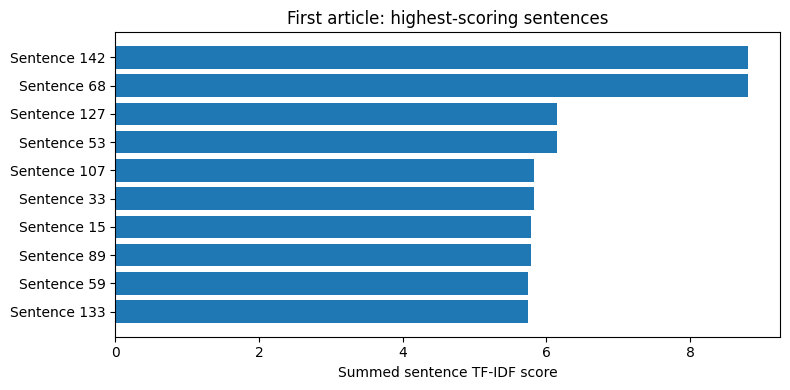

In [47]:
# summarise first article
def split_sentences(text):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+(?=[A-Z])', text)
            if len(s.split()) >= 8]

def extractive_summary(text, count=5):
    sentences = split_sentences(text)
    if not sentences:
        return [], []
    matrix = TfidfVectorizer(stop_words='english').fit_transform(sentences)
    scores = np.asarray(matrix.sum(axis=1)).ravel()
    selected = sorted(np.argsort(scores)[-min(count, len(sentences)):])
    return [sentences[i] for i in selected], [(i + 1, scores[i]) for i in np.argsort(scores)[-10:][::-1]]

first_summary, sentence_ranks = extractive_summary(corpus.loc[0, 'cleaned_content'])
print('FIRST ARTICLE SUMMARY:\n', '\n'.join(first_summary))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([f'Sentence {i}' for i, _ in sentence_ranks][::-1],
        [score for _, score in sentence_ranks][::-1])
ax.set_xlabel('Summed sentence TF-IDF score')
ax.set_title('First article: highest-scoring sentences')
plt.tight_layout()
plt.show()

### Individual Summarisation Interpretation

The first research article was summarised using TF-IDF-based extractive summarisation. Sentences were represented using TF-IDF weights and ranked according to their summed feature scores. The five highest-scoring sentences were selected and arranged in their original document order.

The visualisation illustrates the ten highest sentence scores, highlighting sentences containing terms that receive greater TF-IDF weight.

A limitation of this approach is that longer sentences may accumulate higher scores because they contain more terms. Additionally, TF-IDF evaluates lexical importance rather than semantic understanding, meaning that highly ranked sentences may not always provide the most coherent or comprehensive summary.

### Aggregate Document Summarisation

The remaining four research articles were analysed using centroid-based extractive summarisation. Unlike the first article, which was summarised using individual sentence TF-IDF scores, this approach uses cosine similarity to identify sentences that are representative of the combined document collection.

Sentences were filtered to reduce the inclusion of metadata, incomplete fragments and citation-heavy passages. TF-IDF vectors were generated across the remaining articles, and a shared corpus centroid was calculated.

The two highest-ranked valid sentences from each article were selected to provide coverage across the collection. Their average cosine similarity scores were visualised to compare how closely the selected sentences aligned with the central vocabulary of the corpus.

AGGREGATE SUMMARY:

research_2:
- Reflexivity is crucial throughout all phases of the research process, including the formulation of a research question, collection and analysis of data, and drawing conclusions (Bradbury-Jones, 2007; Guillemin and Gillam, 2004).
- Thus, it enhances the quality of the research by allowing researchers to ponder the ways in which who they are may both assist and hinder the process of co-constructing meanings (Lietz et al., 2006), frees them to handle and present the data better, and consider its complex meanings and contribution to the understanding of social phenomena and of the process involved in knowledge production.

research_3:
- This blend is most obvious in developmental research, those studies that involve the production of knowledge with the ultimate aim of improving the processes of instructional design, development, and evaluation.
- While results from research in these areas impact the development process, the study of variables embedded in s

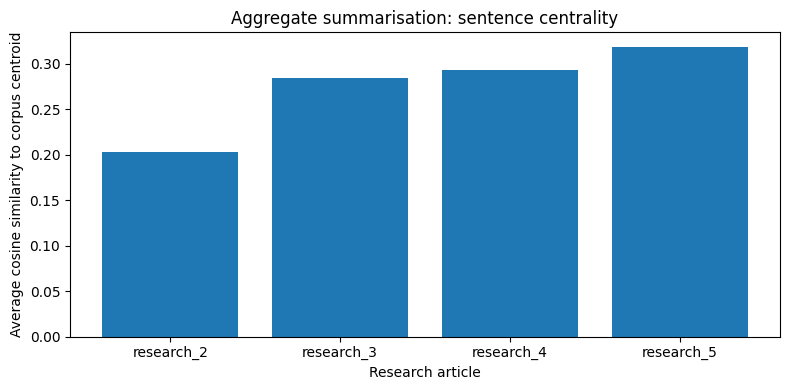

In [48]:
# summarise remaining articles
from sklearn.metrics.pairwise import cosine_similarity

def valid_sentence(sentence):
    words = sentence.split()
    lower = sentence.lower()

    if not 12 <= len(words) <= 65:
        return False

    excluded = [
        "keywords:",
        "corresponding author",
        "doi:",
        "copyright",
        "all rights reserved",
        "university press",
        "http",
        "www."
    ]

    if any(term in lower for term in excluded):
        return False

    # exclude citation-heavy sentences
    citations = re.findall(r"\([^)]*\d{4}[^)]*\)", sentence)

    if len(citations) > 2:
        return False

    # exclude fragments without sentence punctuation
    if not sentence.endswith((".", "!", "?")):
        return False

    return True


# prepare sentences
remaining = corpus.iloc[1:].copy()

rows = [
    (article_id, sentence)
    for article_id, text in zip(
        remaining["article_id"],
        remaining["cleaned_content"]
    )
    for sentence in split_sentences(text)
    if valid_sentence(sentence)
]

sentence_df = pd.DataFrame(
    rows,
    columns=["article_id", "sentence"]
)

if sentence_df.empty:
    raise ValueError("No valid sentences available for summarisation.")

# calculate sentence similarity
vectorizer = TfidfVectorizer(
    stop_words="english",
    min_df=2
)

sentence_matrix = vectorizer.fit_transform(
    sentence_df["sentence"]
)

centroid = np.asarray(sentence_matrix.mean(axis=0))

sentence_df["centrality"] = cosine_similarity(
    sentence_matrix,
    centroid
).ravel()

# select two sentences per article
aggregate_summary = (
    sentence_df
    .sort_values("centrality", ascending=False)
    .groupby("article_id", group_keys=False)
    .head(2)
    .sort_values("article_id")
)

# display aggregate summary
print("AGGREGATE SUMMARY:\n")

for article_id, group in aggregate_summary.groupby("article_id"):
    print(f"{article_id}:")

    for sentence in group["sentence"]:
        print(f"- {sentence}")

    print()

# visualise average centrality
summary_scores = (
    aggregate_summary
    .groupby("article_id")["centrality"]
    .mean()
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(summary_scores.index, summary_scores.values)

ax.set_xlabel("Research article")
ax.set_ylabel("Average cosine similarity to corpus centroid")
ax.set_title("Aggregate summarisation: sentence centrality")

plt.tight_layout()
plt.show()

### Aggregate Summarisation Interpretation

The aggregate summarisation approach identified representative sentences from the remaining four research articles using TF-IDF and cosine similarity.

The articles address different aspects of research methodology, including researcher reflexivity, developmental research, measurement reliability and triangulation. 

The visualisation compares the average cosine similarity scores of the selected sentences across the articles. Higher scores indicate stronger lexical similarity to the combined corpus centroid.